<a href="https://colab.research.google.com/github/Blackk-dotcom/Data-Science-project/blob/main/Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving DSA1101_Practical_Assignments_Datasets (1).xlsx to DSA1101_Practical_Assignments_Datasets (1).xlsx


In [2]:
!pip install pandas numpy matplotlib seaborn scikit-learn openpyxl


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
df = pd.read_excel(
    'DSA1101_Practical_Assignments_Datasets (1).xlsx',
    sheet_name='A2_Retail_Sales'
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
df.head()

,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES
0,TX0001,2025-03-20,Coast,Food,2,409.65,0.15,Mobile Money,Store,696.40
1,TX0002,2025-06-29,NaN,Food,8,1047.14,0.00,Mobile Money,Store,8377.12
2,TX0003,2025-06-02,Coast,Clothing,1,1374.69,0.00,Card,Store,1374.69
3,TX0004,2025-04-17,Coast,Clothing,3,3861.90,0.00,Cash,Store,11585.70
4,TX0005,2025-01-05,Western,Food,1,701.62,0.15,Mobile Money,Online,596.38


In [7]:
print("Rows and columns:", df.shape)


Rows and columns: (262, 10)


In [8]:
import pandas as pd

df = pd.read_excel(
    'DSA1101_Practical_Assignments_Datasets (1).xlsx',
    sheet_name='A2_Retail_Sales'
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [9]:
df.head()

,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES
0,TX0001,2025-03-20,Coast,Food,2,409.65,0.15,Mobile Money,Store,696.40
1,TX0002,2025-06-29,NaN,Food,8,1047.14,0.00,Mobile Money,Store,8377.12
2,TX0003,2025-06-02,Coast,Clothing,1,1374.69,0.00,Card,Store,1374.69
3,TX0004,2025-04-17,Coast,Clothing,3,3861.90,0.00,Cash,Store,11585.70
4,TX0005,2025-01-05,Western,Food,1,701.62,0.15,Mobile Money,Online,596.38


In [11]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset dimensions:", df.shape)


Number of rows: 262
Number of columns: 10
Dataset dimensions: (262, 10)


In [12]:
print("Column names in the dataset:")

for column in df.columns:
    print(column)

Column names in the dataset:
Transaction_ID
Date
Region
Product_Category
Units_Sold
Unit_Price_KES
Discount_Rate
Payment_Method
Sales_Channel
Revenue_KES


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 262 entries, 0 to 261
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction_ID    262 non-null    object        
 1   Date              262 non-null    datetime64[ns]
 2   Region            257 non-null    object        
 3   Product_Category  262 non-null    object        
 4   Units_Sold        262 non-null    int64         
 5   Unit_Price_KES    257 non-null    float64       
 6   Discount_Rate     262 non-null    float64       
 7   Payment_Method    257 non-null    object        
 8   Sales_Channel     262 non-null    object        
 9   Revenue_KES       262 non-null    float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(5)
memory usage: 20.6+ KB


In [14]:
df.describe()

,Date,Units_Sold,Unit_Price_KES,Discount_Rate,Revenue_KES
count,262,262.000000,257.000000,262.000000,262.000000
mean,2025-04-03 10:15:34.351144960,4.973282,7143.780156,0.074809,25089.461908
min,2025-01-01 00:00:00,1.000000,81.580000,0.000000,70.540000
25%,2025-02-13 00:00:00,3.000000,1001.510000,0.000000,2934.317500
50%,2025-04-07 12:00:00,5.000000,2483.140000,0.100000,8920.240000
75%,2025-05-25 18:00:00,7.000000,5950.270000,0.100000,22679.162500
max,2025-06-29 00:00:00,100.000000,250000.000000,0.200000,313895.680000
std,NaN,6.341741,17983.687224,0.069170,45980.561641


In [15]:
df.describe(include='all')

,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES
count,262,262,257,262,262.000000,257.000000,262.000000,257,262,262.000000
unique,260,NaN,5,5,NaN,NaN,NaN,4,2,NaN
top,TX0091,NaN,Western,Clothing,NaN,NaN,NaN,Mobile Money,Store,NaN
freq,2,NaN,65,69,NaN,NaN,NaN,120,160,NaN
mean,NaN,2025-04-03 10:15:34.351144960,NaN,NaN,4.973282,7143.780156,0.074809,NaN,NaN,25089.461908
min,NaN,2025-01-01 00:00:00,NaN,NaN,1.000000,81.580000,0.000000,NaN,NaN,70.540000
25%,NaN,2025-02-13 00:00:00,NaN,NaN,3.000000,1001.510000,0.000000,NaN,NaN,2934.317500
50%,NaN,2025-04-07 12:00:00,NaN,NaN,5.000000,2483.140000,0.100000,NaN,NaN,8920.240000
75%,NaN,2025-05-25 18:00:00,NaN,NaN,7.000000,5950.270000,0.100000,NaN,NaN,22679.162500
max,NaN,2025-06-29 00:00:00,NaN,NaN,100.000000,250000.000000,0.200000,NaN,NaN,313895.680000


In [18]:
print("Missing values in each column:")

print(df.isnull().sum())

Missing values in each column:
Transaction_ID      0
Date                0
Region              5
Product_Category    0
Units_Sold          0
Unit_Price_KES      5
Discount_Rate       0
Payment_Method      5
Sales_Channel       0
Revenue_KES         0
dtype: int64


In [19]:
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print(missing_percentage)

Transaction_ID      0.000000
Date                0.000000
Region              1.908397
Product_Category    0.000000
Units_Sold          0.000000
Unit_Price_KES      1.908397
Discount_Rate       0.000000
Payment_Method      1.908397
Sales_Channel       0.000000
Revenue_KES         0.000000
dtype: float64


In [20]:
duplicates = df.duplicated().sum()

print("Total exact duplicate rows:", duplicates)

Total exact duplicate rows: 2


In [21]:
df[df.duplicated(keep=False)]

,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES
20,TX0021,2025-06-09,Western,Electronics,5,32818.79,0.10,Card,Online,147684.56
90,TX0091,2025-05-18,Western,Food,2,433.95,0.05,Bank Transfer,Online,824.50
260,TX0021,2025-06-09,Western,Electronics,5,32818.79,0.10,Card,Online,147684.56
261,TX0091,2025-05-18,Western,Food,2,433.95,0.05,Bank Transfer,Online,824.50


In [22]:
duplicate_ids = df[
    df.duplicated(
        subset=['Transaction_ID'],
        keep=False
    )
]

print("Duplicate transaction identifiers:")
display(duplicate_ids)

Duplicate transaction identifiers:


,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES
20,TX0021,2025-06-09,Western,Electronics,5,32818.79,0.10,Card,Online,147684.56
90,TX0091,2025-05-18,Western,Food,2,433.95,0.05,Bank Transfer,Online,824.50
260,TX0021,2025-06-09,Western,Electronics,5,32818.79,0.10,Card,Online,147684.56
261,TX0091,2025-05-18,Western,Food,2,433.95,0.05,Bank Transfer,Online,824.50


In [23]:
print(
    "Number of duplicate transaction IDs:",
    df['Transaction_ID'].duplicated().sum()
)

Number of duplicate transaction IDs: 2


In [24]:
print("RETAIL DATASET INSPECTION SUMMARY")
print("=" * 40)

print("Total records:", df.shape[0])
print("Total columns:", df.shape[1])

print("Total missing values:",
      df.isnull().sum().sum())

print("Total duplicate rows:",
      df.duplicated().sum())

print("Duplicate transaction IDs:",
      df['Transaction_ID'].duplicated().sum())

print("\nDataset inspection completed.")

RETAIL DATASET INSPECTION SUMMARY
Total records: 262
Total columns: 10
Total missing values: 15
Total duplicate rows: 2
Duplicate transaction IDs: 2

Dataset inspection completed.


In [25]:
# Convert Date column to datetime format

df['Date'] = pd.to_datetime(
    df['Date'],
    errors='coerce'
)

# Display the first five dates
print(df['Date'].head())

# Check the data type
print("\nDate data type:")
print(df['Date'].dtype)

0   2025-03-20
1   2025-06-29
2   2025-06-02
3   2025-04-17
4   2025-01-05
Name: Date, dtype: datetime64[ns]

Date data type:
datetime64[ns]


In [26]:
# Define numeric columns

numeric_columns = [
    'Units_Sold',
    'Unit_Price_KES',
    'Discount_Rate',
    'Revenue_KES'
]

# Convert columns into numeric data types

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors='coerce'
    )

# Display data types

print("Updated data types:")
print(df[numeric_columns].dtypes)

Updated data types:
Units_Sold          int64
Unit_Price_KES    float64
Discount_Rate     float64
Revenue_KES       float64
dtype: object


In [27]:
# Display the first ten records

display(
    df[
        [
            'Units_Sold',
            'Unit_Price_KES',
            'Discount_Rate',
            'Revenue_KES'
        ]
    ].head(10)
)

,Units_Sold,Unit_Price_KES,Discount_Rate,Revenue_KES
0,2,409.65,0.15,696.40
1,8,1047.14,0.00,8377.12
2,1,1374.69,0.00,1374.69
3,3,3861.90,0.00,11585.70
4,1,701.62,0.15,596.38
5,7,8560.44,0.00,59923.08
6,3,1983.68,0.00,5951.04
7,100,11973.82,0.05,68250.77
8,5,30934.86,0.05,146940.58
9,8,921.14,0.10,6632.21


In [28]:
# Check missing values in numeric columns

print("Missing numeric values:")

print(df[numeric_columns].isnull().sum())

Missing numeric values:
Units_Sold        0
Unit_Price_KES    5
Discount_Rate     0
Revenue_KES       0
dtype: int64


In [29]:
# Identify quantities that are zero or negative

invalid_units = df[
    df['Units_Sold'] <= 0
]

print("Invalid quantities sold:")
display(invalid_units)

print(
    "Number of invalid quantity records:",
    len(invalid_units)
)

Invalid quantities sold:


,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES


Number of invalid quantity records: 0


In [30]:
# Identify zero or negative unit prices

invalid_prices = df[
    df['Unit_Price_KES'] <= 0
]

print("Invalid unit prices:")
display(invalid_prices)

print(
    "Number of invalid price records:",
    len(invalid_prices)
)

Invalid unit prices:


,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES


Number of invalid price records: 0


In [31]:
# Discount rate should be between 0 and 1

invalid_discounts = df[
    (df['Discount_Rate'] < 0) |
    (df['Discount_Rate'] > 1)
]

print("Invalid discount rates:")
display(invalid_discounts)

print(
    "Number of invalid discount records:",
    len(invalid_discounts)
)

Invalid discount rates:


,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES


Number of invalid discount records: 0


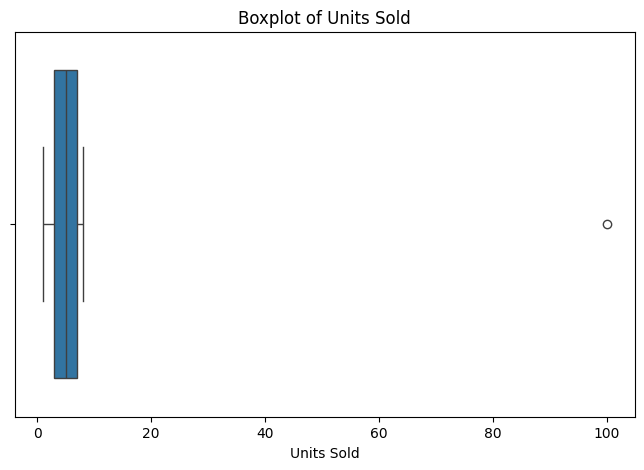

In [32]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df['Units_Sold'])

plt.title('Boxplot of Units Sold')
plt.xlabel('Units Sold')

plt.show()

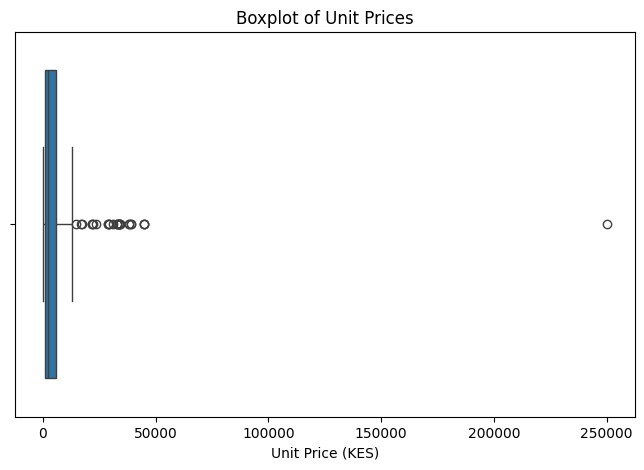

In [33]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df['Unit_Price_KES'])

plt.title('Boxplot of Unit Prices')
plt.xlabel('Unit Price (KES)')

plt.show()

In [34]:
# Display updated dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 262 entries, 0 to 261
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction_ID    262 non-null    object        
 1   Date              262 non-null    datetime64[ns]
 2   Region            257 non-null    object        
 3   Product_Category  262 non-null    object        
 4   Units_Sold        262 non-null    int64         
 5   Unit_Price_KES    257 non-null    float64       
 6   Discount_Rate     262 non-null    float64       
 7   Payment_Method    257 non-null    object        
 8   Sales_Channel     262 non-null    object        
 9   Revenue_KES       262 non-null    float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(5)
memory usage: 20.6+ KB


In [35]:
print("QUESTION 3: DATA TYPE VERIFICATION")
print("=" * 45)

print("\nDate data type:")
print(df['Date'].dtype)

print("\nNumeric data types:")
print(df[numeric_columns].dtypes)

print("\nMissing values:")
print(df[numeric_columns + ['Date']].isnull().sum())

print("\nInvalid quantities:",
      (df['Units_Sold'] <= 0).sum())

print("Invalid prices:",
      (df['Unit_Price_KES'] <= 0).sum())

print("Invalid discounts:",
      (
          (df['Discount_Rate'] < 0) |
          (df['Discount_Rate'] > 1)
      ).sum())

print("\nQuestion 3 completed successfully!")

QUESTION 3: DATA TYPE VERIFICATION

Date data type:
datetime64[ns]

Numeric data types:
Units_Sold          int64
Unit_Price_KES    float64
Discount_Rate     float64
Revenue_KES       float64
dtype: object

Missing values:
Units_Sold        0
Unit_Price_KES    5
Discount_Rate     0
Revenue_KES       0
Date              0
dtype: int64

Invalid quantities: 0
Invalid prices: 0
Invalid discounts: 0

Question 3 completed successfully!


In [36]:
# Calculate revenue using the given formula

df['Calculated_Revenue_KES'] = (
    df['Units_Sold'] *
    df['Unit_Price_KES'] *
    (1 - df['Discount_Rate'])
)

print("Revenue recalculated successfully!")

Revenue recalculated successfully!


In [37]:
# Display original and calculated revenue

display(
    df[
        [
            'Units_Sold',
            'Unit_Price_KES',
            'Discount_Rate',
            'Revenue_KES',
            'Calculated_Revenue_KES'
        ]
    ].head(10)
)

,Units_Sold,Unit_Price_KES,Discount_Rate,Revenue_KES,Calculated_Revenue_KES
0,2,409.65,0.15,696.40,696.405
1,8,1047.14,0.00,8377.12,8377.120
2,1,1374.69,0.00,1374.69,1374.690
3,3,3861.90,0.00,11585.70,11585.700
4,1,701.62,0.15,596.38,596.377
5,7,8560.44,0.00,59923.08,59923.080
6,3,1983.68,0.00,5951.04,5951.040
7,100,11973.82,0.05,68250.77,1137512.900
8,5,30934.86,0.05,146940.58,146940.585
9,8,921.14,0.10,6632.21,6632.208


In [38]:
# Calculate the difference

df['Revenue_Difference'] = (
    df['Revenue_KES'] -
    df['Calculated_Revenue_KES']
)

print("Revenue differences calculated successfully!")

display(
    df[
        [
            'Revenue_KES',
            'Calculated_Revenue_KES',
            'Revenue_Difference'
        ]
    ].head(10)
)

Revenue differences calculated successfully!


,Revenue_KES,Calculated_Revenue_KES,Revenue_Difference
0,696.40,696.405,-0.005
1,8377.12,8377.120,0.000
2,1374.69,1374.690,0.000
3,11585.70,11585.700,0.000
4,596.38,596.377,0.003
5,59923.08,59923.080,0.000
6,5951.04,5951.040,0.000
7,68250.77,1137512.900,-1069262.130
8,146940.58,146940.585,-0.005
9,6632.21,6632.208,0.002


In [39]:
# Set rounding tolerance

tolerance = 0.01

# Compare the original and calculated revenue

df['Revenue_Status'] = np.where(
    df['Revenue_Difference'].abs() <= tolerance,
    'Matches',
    'Does Not Match'
)

# Display comparison results

display(
    df[
        [
            'Revenue_KES',
            'Calculated_Revenue_KES',
            'Revenue_Difference',
            'Revenue_Status'
        ]
    ]
)

,Revenue_KES,Calculated_Revenue_KES,Revenue_Difference,Revenue_Status
0,696.40,696.405,-0.005,Matches
1,8377.12,8377.120,0.000,Matches
2,1374.69,1374.690,0.000,Matches
3,11585.70,11585.700,0.000,Matches
4,596.38,596.377,0.003,Matches
...,...,...,...,...
257,69598.36,69598.360,0.000,Matches
258,14040.86,14040.864,-0.004,Matches
259,1951.04,1951.038,0.002,Matches
260,147684.56,147684.555,0.005,Matches


In [40]:
# Identify records where revenue does not match

inconsistent_revenue = df[
    df['Revenue_Status'] == 'Does Not Match'
]

print(
    "Number of inconsistent revenue records:",
    len(inconsistent_revenue)
)

display(inconsistent_revenue)

Number of inconsistent revenue records: 7


,Transaction_ID,Date,Region,Product_Category,Units_Sold,Unit_Price_KES,Discount_Rate,Payment_Method,Sales_Channel,Revenue_KES,Calculated_Revenue_KES,Revenue_Difference,Revenue_Status
7,TX0008,2025-02-24,Coast,Home,100,11973.82,0.05,Card,Store,68250.77,1137512.9,-1069262.13,Does Not Match
18,TX0019,2025-05-26,Coast,Electronics,6,250000.00,0.05,Card,Online,116623.31,1425000.0,-1308376.69,Does Not Match
77,TX0078,2025-05-30,Rift Valley,Food,7,NaN,0.05,Mobile Money,Store,1626.19,NaN,NaN,Does Not Match
82,TX0083,2025-05-25,Nairobi,Clothing,2,NaN,0.00,Mobile Money,Online,4456.96,NaN,NaN,Does Not Match
96,TX0097,2025-04-02,Western,Food,6,NaN,0.20,Mobile Money,Online,5267.52,NaN,NaN,Does Not Match
130,TX0131,2025-01-22,Coast,Home,2,NaN,0.00,Card,Store,2871.58,NaN,NaN,Does Not Match
211,TX0212,2025-06-06,Coast,Food,6,NaN,0.00,NaN,Store,4158.60,NaN,NaN,Does Not Match


In [41]:
# Count revenue matches and mismatches

revenue_counts = df['Revenue_Status'].value_counts()

print("Revenue comparison summary:")
print(revenue_counts)

# Calculate percentages

revenue_percentages = (
    df['Revenue_Status']
    .value_counts(normalize=True) * 100
)

print("\nRevenue comparison percentages:")
print(revenue_percentages)

Revenue comparison summary:
Revenue_Status
Matches           255
Does Not Match      7
Name: count, dtype: int64

Revenue comparison percentages:
Revenue_Status
Matches           97.328244
Does Not Match     2.671756
Name: proportion, dtype: float64


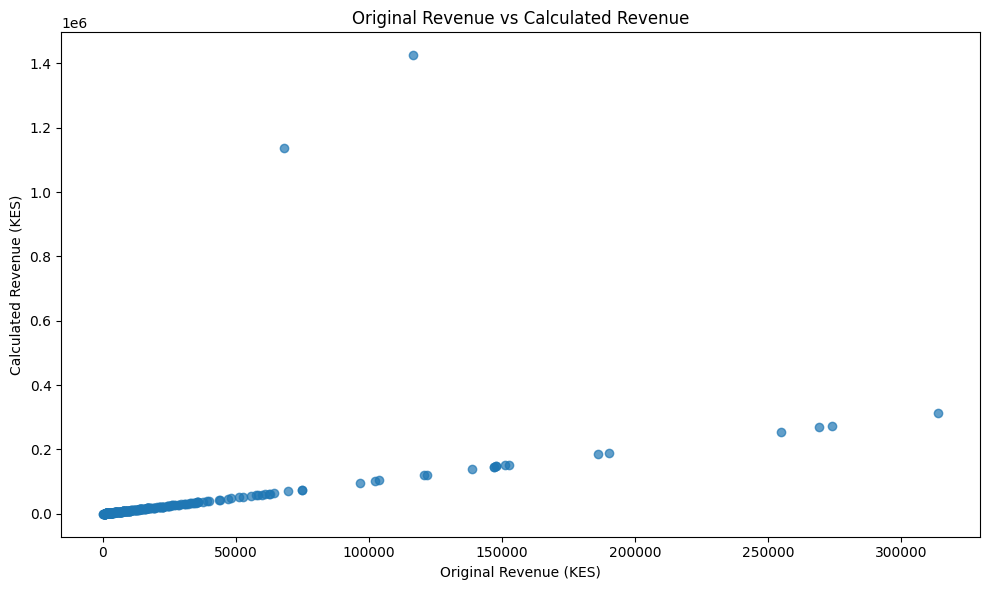

In [42]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df['Revenue_KES'],
    df['Calculated_Revenue_KES'],
    alpha=0.7
)

plt.xlabel('Original Revenue (KES)')
plt.ylabel('Calculated Revenue (KES)')

plt.title('Original Revenue vs Calculated Revenue')

plt.tight_layout()
plt.show()

In [43]:
print("QUESTION 4: REVENUE COMPARISON")
print("=" * 45)

print(
    "Total Original Revenue: KES",
    round(df['Revenue_KES'].sum(), 2)
)

print(
    "Total Calculated Revenue: KES",
    round(df['Calculated_Revenue_KES'].sum(), 2)
)

print(
    "Total Revenue Difference: KES",
    round(df['Revenue_Difference'].sum(), 2)
)

print(
    "Matching Records:",
    (df['Revenue_Status'] == 'Matches').sum()
)

print(
    "Inconsistent Records:",
    (df['Revenue_Status'] == 'Does Not Match').sum()
)

print("\nQuestion 4 completed successfully!")

QUESTION 4: REVENUE COMPARISON
Total Original Revenue: KES 6573439.02
Total Calculated Revenue: KES 8932696.98
Total Revenue Difference: KES -2377638.81
Matching Records: 255
Inconsistent Records: 7

Question 4 completed successfully!
